### Ler dados

In [1]:
claims <- read.csv("claims.csv")[, 1:9]

claims$cmsinistros <- claims$csin/claims$nsin

In [2]:
caminho <- "C:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MLG/"
envelopes <- paste0(caminho, "Envelopes/")

### Analise descritiva

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  200.0   353.8   643.6  1731.3  1787.6 26507.3 

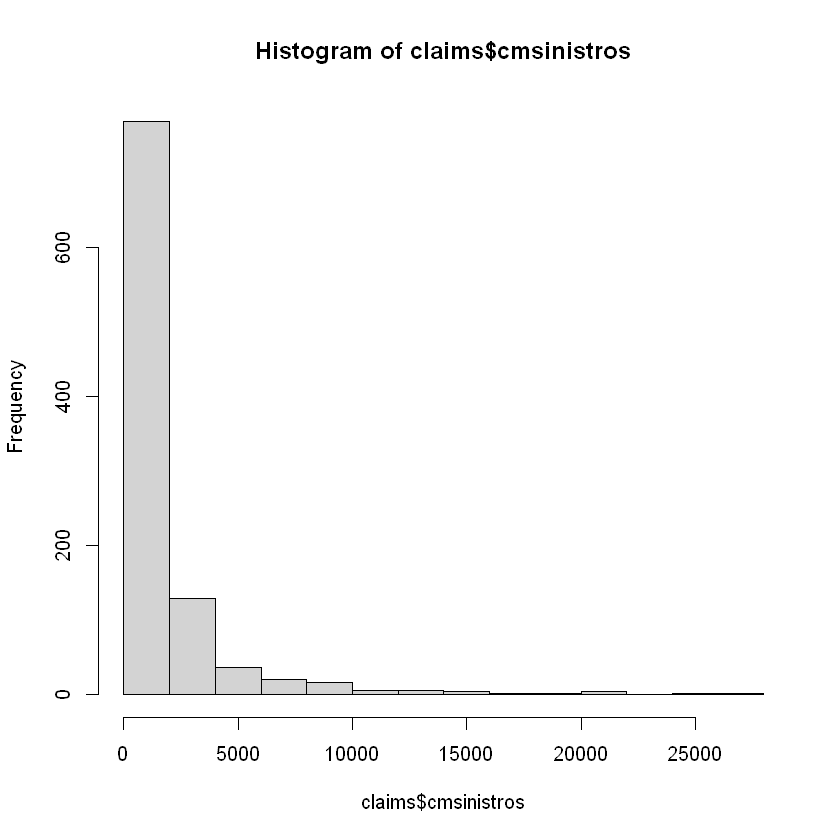

In [3]:
hist(claims$cmsinistros)
summary(claims$cmsinistros)

dá para ver que tem uma forte assimetria

### histograma na escala log

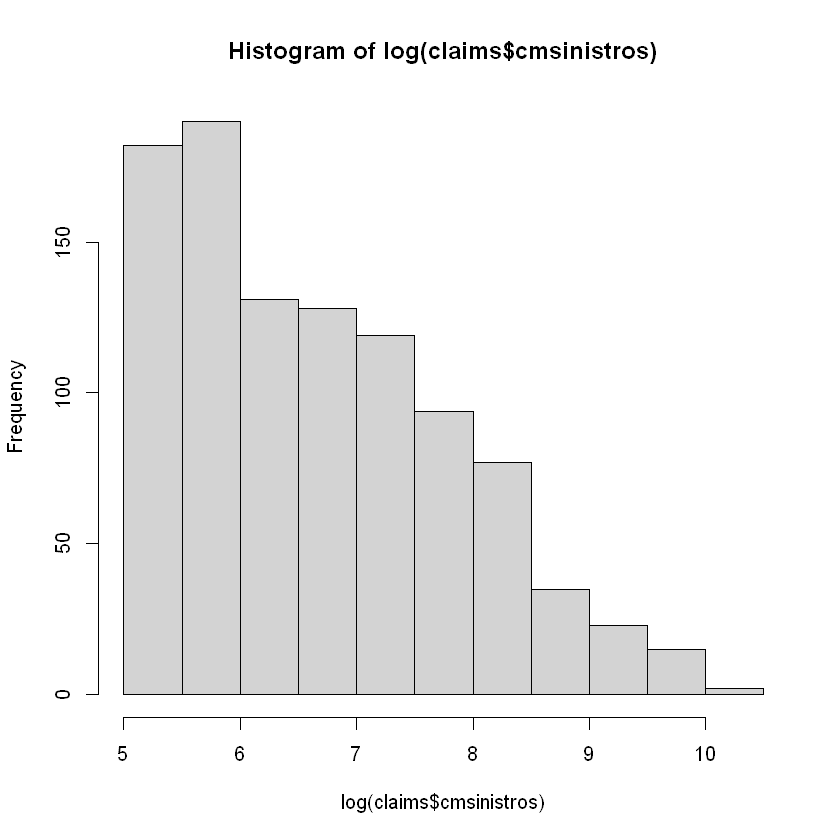

In [4]:
hist(log(claims$cmsinistros))


### Covariaveis continuas:

In [5]:
summary(claims$valorv)
summary(claims$expos)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.000   1.130   1.600   1.859   2.350   7.199 

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.005476 0.443532 0.616016 0.614804 0.848734 0.999316 

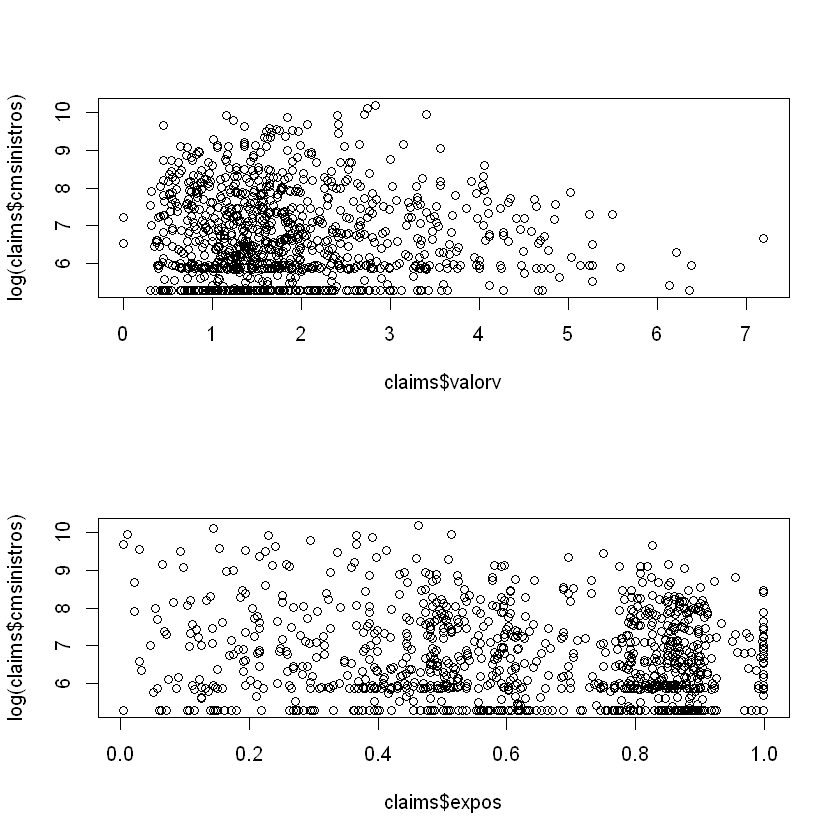

In [6]:
par(mfrow= c(2,1))
plot(claims$valorv,log(claims$cmsinistros))
plot(claims$expos,log(claims$cmsinistros))
par(mfrow =c(1,1))

medidas descritivas por nível das covariveis categoricas, podemos colocar isso mas meio que é de mais...

In [7]:
library(doBy)
summaryBy(cmsinistros~factor(tipov), data=claims, FUN=c(mean, sd, length))
summaryBy(cmsinistros~factor(idadev), data=claims, FUN=c(mean, sd, length))
summaryBy(cmsinistros~factor(genero), data=claims, FUN=c(mean, sd, length))
summaryBy(cmsinistros~factor(areac), data=claims, FUN=c(mean, sd, length))
 

,tipov,cmsinistros.mean,cmsinistros.sd,cmsinistros.length
,<chr>,<dbl>,<dbl>,<dbl>
1,BUS,2620.720,NA,1
2,COUPE,1649.645,1484.195,11
3,HBACK,1751.728,2894.680,272
4,HDTOP,2134.260,4340.020,23
5,MCARA,1284.612,1357.302,4
6,MIBUS,3009.265,5197.407,6
7,PANVN,3017.546,3681.442,11
8,SEDAN,1501.759,2239.136,314
9,STNWG,1723.953,3361.979,268


,idadev,cmsinistros.mean,cmsinistros.sd,cmsinistros.length
,<int>,<dbl>,<dbl>,<dbl>
1,1,1434.774,2477.427,187
2,2,1701.322,3229.394,264
3,3,1784.982,2919.816,309
4,4,1929.715,3013.703,236


,genero,cmsinistros.mean,cmsinistros.sd,cmsinistros.length
,<chr>,<dbl>,<dbl>,<dbl>
1,F,1643.213,2657.231,567
2,M,1847.837,3301.363,429


,areac,cmsinistros.mean,cmsinistros.sd,cmsinistros.length
,<chr>,<dbl>,<dbl>,<dbl>
1,A,1552.275,2431.091,233
2,B,1529.202,2309.836,196
3,C,1722.825,3052.106,313
4,D,1669.050,2810.977,108
5,E,2508.370,4435.586,90
6,F,2102.952,3513.644,56


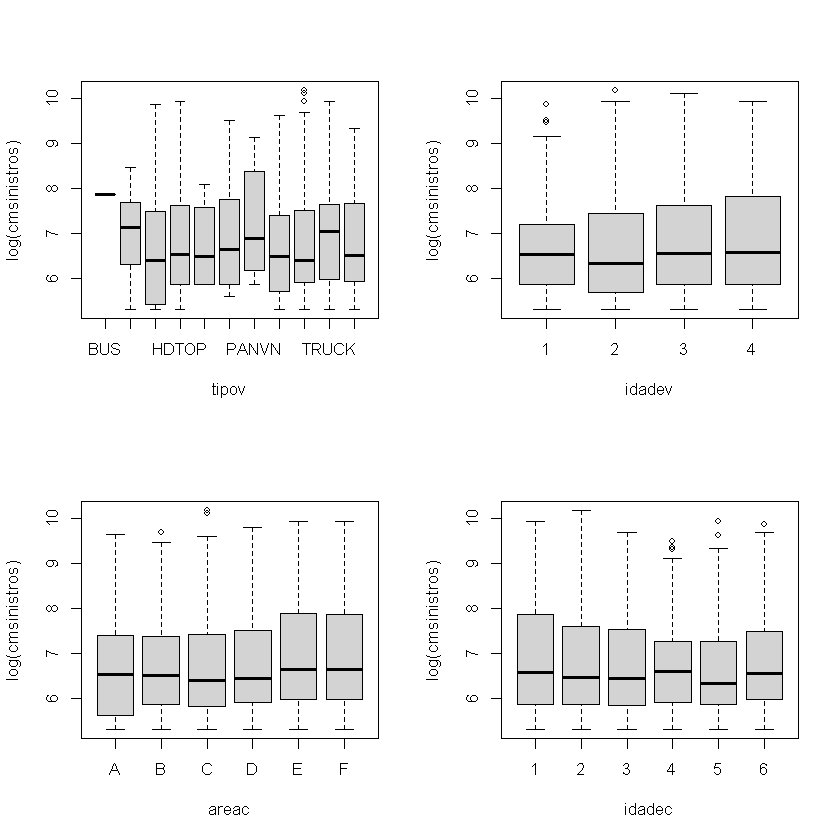

In [8]:
# Boxplots na escala log (mais fáceis de comparar)
par(mfrow=c(2,2))
boxplot(log(cmsinistros) ~ tipov, data=claims)
boxplot(log(cmsinistros) ~ idadev, data=claims)
boxplot(log(cmsinistros) ~ areac, data=claims)
boxplot(log(cmsinistros) ~ idadec, data=claims)
par(mfrow=c(1,1))


### ajustando modelo, supondo phi constante e função de ligação log.

#### gama



In [9]:
aj0_claims <- glm(cmsinistros ~ valorv + expos + factor(tipov) + factor(idadev) +
                    factor(genero) + factor(areac) + factor(idadec),
                  family=Gamma(link="log"), data=claims)
summary(aj0_claims)


Call:
glm(formula = cmsinistros ~ valorv + expos + factor(tipov) + 
    factor(idadev) + factor(genero) + factor(areac) + factor(idadec), 
    family = Gamma(link = "log"), data = claims)

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)         8.418894   1.528312   5.509 4.63e-08 ***
valorv             -0.076800   0.072448  -1.060   0.2894    
expos              -1.033863   0.186007  -5.558 3.52e-08 ***
factor(tipov)COUPE -0.562811   1.551804  -0.363   0.7169    
factor(tipov)HBACK -0.306961   1.492147  -0.206   0.8371    
factor(tipov)HDTOP  0.063335   1.515559   0.042   0.9667    
factor(tipov)MCARA -0.375040   1.655662  -0.227   0.8208    
factor(tipov)MIBUS  0.055133   1.606739   0.034   0.9726    
factor(tipov)PANVN  0.500381   1.552076   0.322   0.7472    
factor(tipov)SEDAN -0.369982   1.489507  -0.248   0.8039    
factor(tipov)STNWG -0.286635   1.484660  -0.193   0.8469    
factor(tipov)TRUCK  0.184836   1.510097   0.122   0.9026    
fac

In [10]:
drop1(aj0_claims, test="F")

,Df,Deviance,AIC,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,1352.251,16742.56,NA,NA
valorv,1,1354.081,16741.42,1.3114470,2.524156e-01
expos,1,1420.161,16772.20,48.6632647,5.624207e-12
factor(tipov),10,1373.822,16732.61,1.5457426,1.181916e-01
factor(idadev),3,1355.127,16737.90,0.6871103,5.600058e-01
factor(genero),1,1353.016,16740.92,0.5487213,4.590201e-01
factor(areac),5,1365.853,16738.90,1.9494650,8.376853e-02
factor(idadec),5,1377.276,16744.22,3.5864698,3.213400e-03


pelos resultados do teste F acima podemos ver que as covariaveis "tipo", "idadev", "genero", "areac" não são significativas no modelo.

### modelo reduzido sem as covariaveis insignificativos

In [11]:
aj1_claims <- glm(cmsinistros ~ valorv + expos + factor(idadec),
                  family=Gamma(link="log"), data=claims)
summary(aj1_claims)


Call:
glm(formula = cmsinistros ~ valorv + expos + factor(idadec), 
    family = Gamma(link = "log"), data = claims)

Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)      8.38638    0.19589  42.813  < 2e-16 ***
valorv          -0.04896    0.04380  -1.118   0.2640    
expos           -1.02395    0.18673  -5.484 5.29e-08 ***
factor(idadec)2 -0.13857    0.17582  -0.788   0.4308    
factor(idadec)3 -0.35338    0.17336  -2.038   0.0418 *  
factor(idadec)4 -0.43338    0.17311  -2.504   0.0125 *  
factor(idadec)5 -0.39072    0.19048  -2.051   0.0405 *  
factor(idadec)6 -0.04850    0.21431  -0.226   0.8210    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 2.220319)

    Null deviance: 1513.4  on 995  degrees of freedom
Residual deviance: 1399.1  on 988  degrees of freedom
AIC: 16745

Number of Fisher Scoring iterations: 8


aic aumentou em só duas unidades.

grafico de diagnostico com gamlss

In [12]:
library(gamlss)
aj3_claims <- gamlss(cmsinistros ~ valorv + expos + factor(idadec), sigma.formula =~ 1,
                     family=GA(mu.link="log", sigma.link="log"), data=claims)
summary(aj3_claims)

Carregando pacotes exigidos: splines

Carregando pacotes exigidos: gamlss.data


Anexando pacote: 'gamlss.data'


O seguinte objeto é mascarado por 'package:datasets':

    sleep


Carregando pacotes exigidos: gamlss.dist

Carregando pacotes exigidos: nlme

Carregando pacotes exigidos: parallel

 **********   GAMLSS Version 5.5-0  ********** 

For more on GAMLSS look at https://www.gamlss.com/

Type gamlssNews() to see new features/changes/bug fixes.




GAMLSS-RS iteration 1: Global Deviance = 16710.06 
GAMLSS-RS iteration 2: Global Deviance = 16710.06 
******************************************************************
Family:  c("GA", "Gamma") 

Call:  gamlss(formula = cmsinistros ~ valorv + expos + factor(idadec),  
    sigma.formula = ~1, family = GA(mu.link = "log",  
        sigma.link = "log"), data = claims) 

Fitting method: RS() 

------------------------------------------------------------------
Mu link function:  log
Mu Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)      8.38642    0.14793  56.691  < 2e-16 ***
valorv          -0.04896    0.03530  -1.387 0.165798    
expos           -1.02401    0.13520  -7.574 8.31e-14 ***
factor(idadec)2 -0.13858    0.12941  -1.071 0.284508    
factor(idadec)3 -0.35338    0.12794  -2.762 0.005848 ** 
factor(idadec)4 -0.43338    0.12779  -3.391 0.000723 ***
factor(idadec)5 -0.39072    0.13933  -2.804 0.005143 ** 
factor(idadec)6 -0.04850    0.15773  -0.308

(as estimativas não mudaram)

******************************************************************
	      Summary of the Quantile Residuals
                           mean   =  -0.03636754 
                       variance   =  0.9624111 
               coef. of skewness  =  1.205201 
               coef. of kurtosis  =  4.35799 
Filliben correlation coefficient  =  0.9491584 
******************************************************************


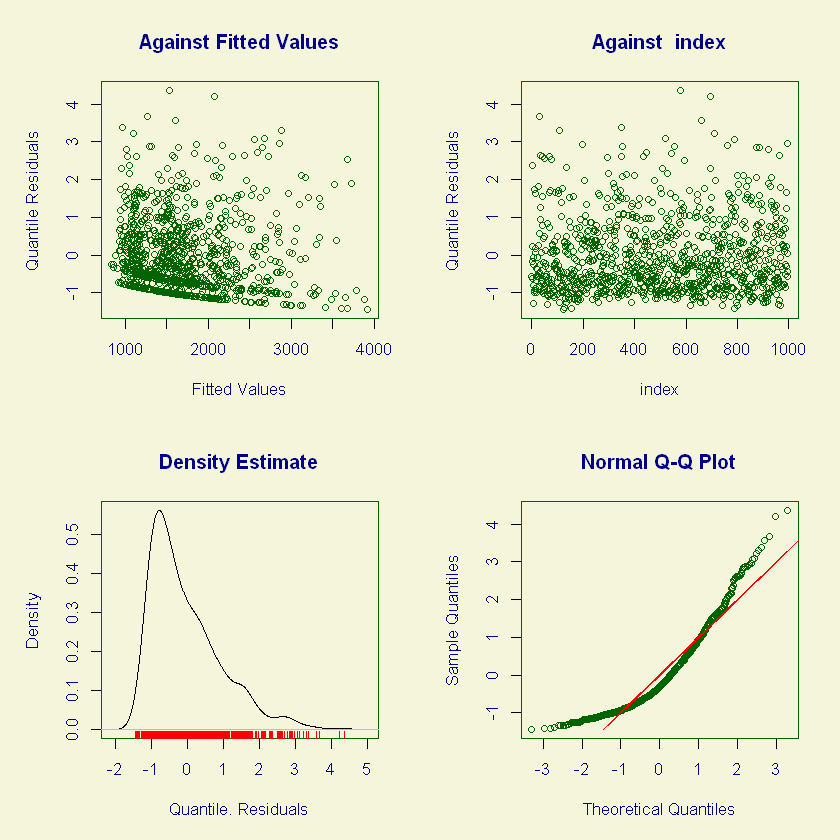

In [13]:
plot(aj3_claims)

parece que o modelo não está muito adequdo:

- residuos quantiliticos não parecem tão aleatorios. e os pontos desviam visualmente bastante da reta da normalidade em qqplot.

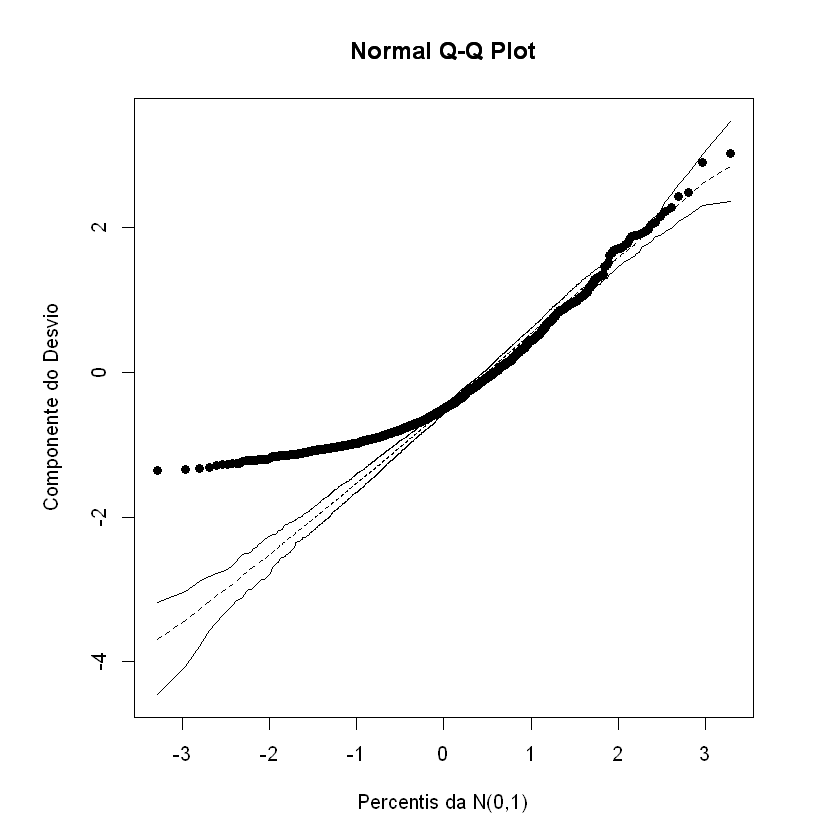

In [15]:
fit.model <- aj1_claims
source(paste0(envelopes, "envelope_gama.R"))

tem muitos pontos fora do envelope, o modelo não tá legal

### normal inversa


In [ ]:
aj0_ni_claims <- glm(
  cmsinistros ~ valorv + expos + factor(tipov) + factor(idadev) +
                 factor(genero) + factor(areac) + factor(idadec),
  family = inverse.gaussian(link = "log"),
  data = claims,
  control = glm.control(maxit = 100, trace = TRUE) # maxit maior, trace para ver o progresso
)

summary(aj0_ni_claims)